# PPKS 06: Svojstva DFT-a i implementacija IDFT-a

***


Svojstva DFT-a opisana u ovom poglavlju su:
1. Linearnost
2. Pomak u DFT-u
3. Simetrija spektra
4. Razmazivanje spektra

***

## 1. Linearnost

Linearnost je jedno od temeljnih svojstava DFT-a. Ono kaže da ako je signal linearna kombinacija jednostavnijih komponenti, možemo svaku komponentu zasebno prebaciti u frekvencijsku domenu i tamo ih zbrojiti.

Za neki par signala $x_1[n]$ i $x_2[n]$ iste duljine $N$ i (realne ili kompleksne) brojeve $c_1$ i $c_2$ vrijedi:
$$
\begin{equation}
DFT\{c_1\cdot x_1[n]+c_2 \cdot x_2[n]\}=c_1 \cdot DFT\{x_1[n]\}+c_2 \cdot DFT\{x_2[n]\}
\end{equation}
$$

Pokazat ćemo da je tako:

$X[k]=\sum_{n=0}^{N-1} x[n] e^{-j 2 \pi\cdot \frac{k}{N} \cdot n}$

$X[k]=\sum_{n=0}^{N-1} (c_1\cdot x_1[n]+c_2 \cdot x_2[n]) e^{-j 2 \pi\cdot \frac{k}{N} \cdot n}$

$X[k]=\sum_{n=0}^{N-1} c_1\cdot x_1[n] e^{-j 2 \pi\cdot \frac{k}{N} \cdot n} +\sum_{n=0}^{N-1}c_2 \cdot x_2[n]e^{-j 2 \pi\cdot \frac{k}{N} \cdot n}$

$X[k]=c_1\cdot \sum_{n=0}^{N-1} x_1[n] e^{-j 2 \pi\cdot \frac{k}{N} \cdot n} +c_2\cdot \sum_{n=0}^{N-1} x_2[n]e^{-j 2 \pi\cdot \frac{k}{N} \cdot n}$

$X[k]=c_1 \cdot DFT\{x_1[n]\}+c_2 \cdot DFT\{x_2[n]\}$


Linearnost osigurava da se odnosi između signala u vremenskoj domeni dosljedno preslikavaju u frekvencijsku domenu. Ako je signal linearna kombinacija više komponenti, tada je i njegov spektar jednak istoj linearnoj kombinaciji spektara tih komponenti. Drugim riječima, linearnost omogućuje da složene signale razumijemo kao zbroj jednostavnih komponenti u frekvencijskoj domeni.



***

U nastavku je na primjeru dva signala $\cos(2\pi \cdot \frac{1}{N} \cdot n)$ i $\sin(2\pi \cdot \frac{3}{N} \cdot n)$ i skalara $c_1=2$ i $c_2=0.5$ programski pokazano svojstvo linearnosti DFT-a. Vidimo da su spektri isti bez obzira radimo li prvo DFT nad svakim signalom posebno ili ih prvo skaliramo i zbrojimo pa nad rezultatom radimo DFT.
 

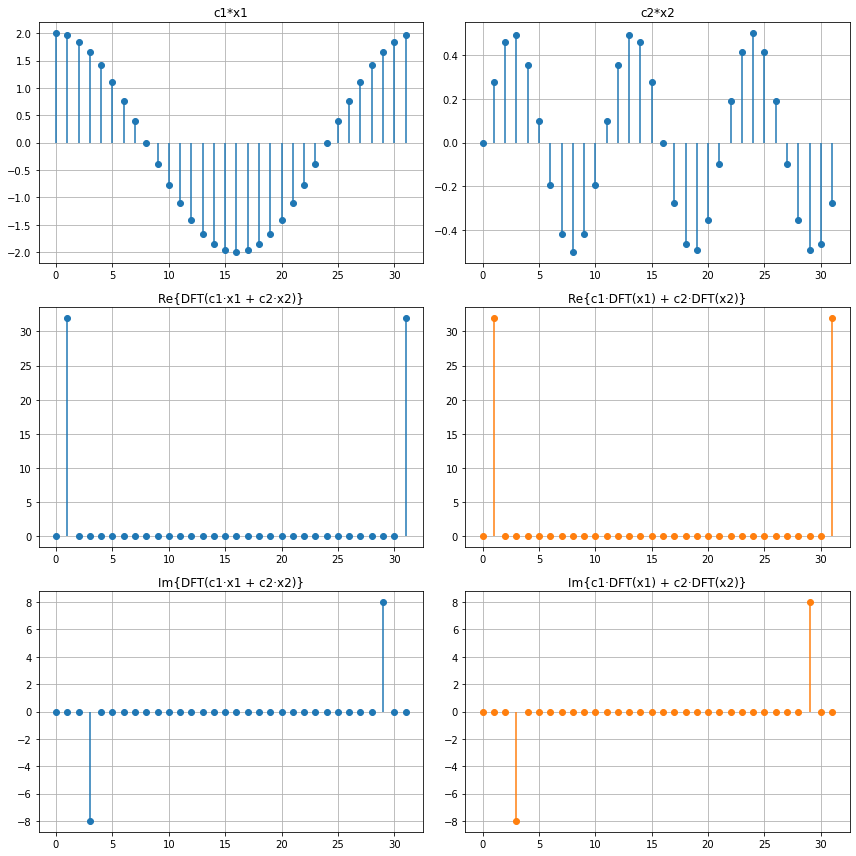

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import scipy


N = 32
n = np.arange(N)
x1 = np.cos(2 * np.pi * 1 / N * n)   # k=1
x2 = np.sin(2 * np.pi * 3 / N * n)   # k=3

c1, c2 = 2, 0.5
z = c1*x1 + c2*x2

# Izračun DFT-ova
X1 = scipy.fft.fft(x1)
X2 = scipy.fft.fft(x2)
Z1 = scipy.fft.fft(z)         # DFT linearne kombinacije
Z2 = c1 * X1 + c2 * X2        # linearna kombinacija pojedinačnih DFT-ova



fig, axs = plt.subplots(3, 2, figsize=(12, 12))


axs[0, 0].stem(n, c1*x1, basefmt=" ", linefmt='C0-', markerfmt='C0o')
axs[0, 0].set_title('c1*x1')
axs[0, 0].grid()

axs[0, 1].stem(n, c2*x2, basefmt=" ", linefmt='C0-', markerfmt='C0o')
axs[0, 1].set_title('c2*x2')
axs[0, 1].grid()

axs[1, 0].stem(n, np.real(Z1), basefmt=" ", linefmt='C0-', markerfmt='C0o')
axs[1, 0].set_title('Re{DFT(c1·x1 + c2·x2)}')
axs[1, 0].grid()

axs[1, 1].stem(n, np.real(Z2), basefmt=" ", linefmt='C1-', markerfmt='C1o')
axs[1, 1].set_title('Re{c1·DFT(x1) + c2·DFT(x2)}')
axs[1, 1].grid()

axs[2, 0].stem(n, np.imag(Z1), basefmt=" ", linefmt='C0-', markerfmt='C0o')
axs[2, 0].set_title('Im{DFT(c1·x1 + c2·x2)}')
axs[2, 0].grid()

axs[2, 1].stem(n, np.imag(Z2), basefmt=" ", linefmt='C1-', markerfmt='C1o')
axs[2, 1].set_title('Im{c1·DFT(x1) + c2·DFT(x2)}')
axs[2, 1].grid()


plt.tight_layout()

plt.show()


***

## 2. Pomak u DFT-u

Što ako signal prije DFT-a pomaknemo u vremenu? Kako će onda izgledati frekvencijska domena u odnosu na isti, ali nepomaknuti signal?

Valja napomenuti kako je pomak kod signala u DFT-u drugačiji od običnog pomaka koji smo radili ranije. Naime, za DFT pretpostavljamo da se signal periodički ponavlja svakih $N$ uzoraka pa se u tom slučaju radi o __kružnom pomaku__ u kojem se pomaknuti dio prebacuje na početak signala tako da broj uzoraka ostane isti. 

Svojstvo pomaka u DFT-u signala $x[n]$ s $N$ uzoraka za $d$ uzoraka pišemo na sljedeći način:

Ako $DFT\{x[n]\}=X[k]$ tada za $y[n]=x[(n-d)\text{ mod }N]$ ($\text{ mod }N$ je zbog kružnog pomaka) vrijedi:

$$
\begin{equation}
Y[k]=X[k] \cdot e^{-j 2 \pi\cdot \frac{k}{N} \cdot d}
\end{equation}
$$

Kružni pomak signala u vremenskoj domeni za $d$ uzoraka rezultirat će množenjem svake frekvencijske komponente faktorom $e^{-j 2 \pi\cdot \frac{k}{N} \cdot d}$ u frekvencijskoj. 
Magnituda $|X[k]|$ (koja nam govori koliko je $k$-tog referentnog signala u $x[n]$) će ostati ista jer su u signalu i dalje iste frekvencije, ali će se kut $\angle X[k]$ promijeniti za $-2\pi \frac{k}{N}d$, odnosno faza se linearno mijenja s frekvencijskim indeksom $k$. Dakle, ne mijenjaju se same frekvencije u signalu pa magnituda ostaje ista, ali se mijenjaju početne točke referentnih signala pa se mijenja kut, odnosno faza kompleksnog broja $X[k]$.

Primijetimo da spektar originalnog signala $X[k]$ zapravo množimo faktorom koji je bio rezultat primjene DFT-a na pomaknuti jedinični impuls iz prošlog poglavlja ($\text{DFT}\{\delta[n-d]\}=e^{-j 2 \pi\cdot \frac{k}{N} \cdot d}$). Sjećamo se da je i tamo magnituda ostala jednaka, a mijenjala se faza.

Pokazat ćemo kako smo došli do tog izraza:

$
Y[k]=\sum_{n=0}^{N-1} x[n-d] e^{-j 2 \pi\cdot \frac{k}{N} \cdot n}
$

Uvodimo zamjenu $m=n-d$ i mijenjamo granice sume:

$
Y[k]=\sum_{m=-d}^{N-1-d} x[m] e^{-j 2 \pi\cdot \frac{k}{N} \cdot (m+d)}
$

$
Y[k]=\sum_{m=-d}^{N-1-d} x[m] e^{-j 2 \pi\cdot \frac{k}{N} \cdot m} \cdot e^{-j 2 \pi\cdot \frac{k}{N} \cdot d}
$

Budući da drugi dio izraza ne ovisi o $m$, možemo cijeli taj dio izvući izvan sume pa dobijemo:

$
Y[k]=e^{-j 2 \pi\cdot \frac{k}{N} \cdot d} \cdot \sum_{m=-d}^{N-1-d} x[m] e^{-j 2 \pi\cdot \frac{k}{N} \cdot m} 
$

U tom izrazu možemo primijetiti da, iako sumiramo po $m$, i dalje se radi o istih $N$ uzoraka pa možemo jednostavno napisati da cijela suma zapravo predstavlja $X[k]$:

$
Y[k]=X[k] \cdot e^{-j 2 \pi\cdot \frac{k}{N} \cdot d}
$

U nastavku je pokazano kako se za različite pomake mijenja faza, a magnituda ostaje ista.



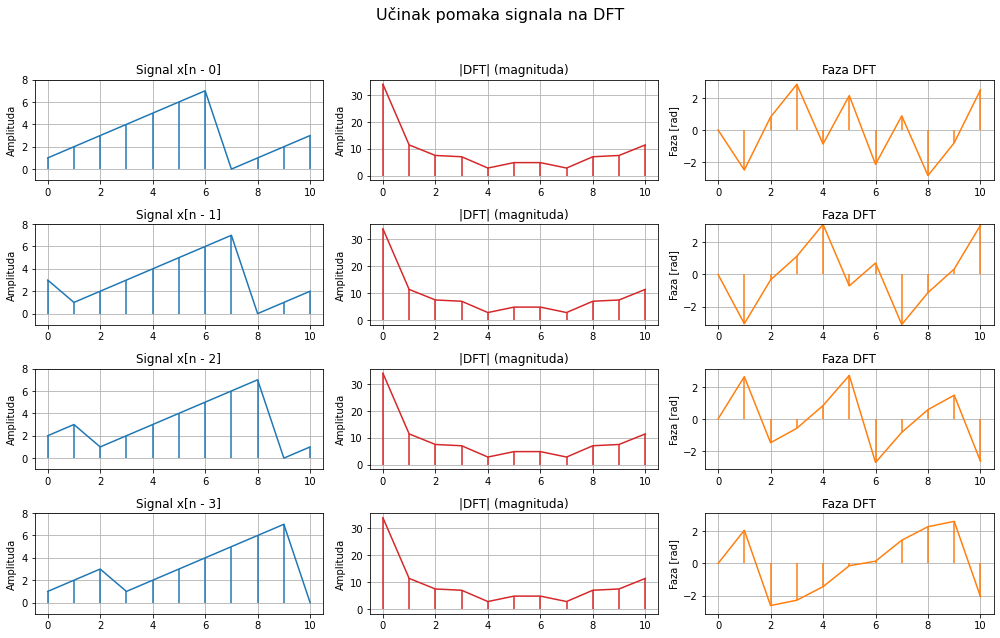

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, ifft

# Originalni signal
x = np.array([1, 2, 3, 4, 5, 6, 7, 0, 1, 2, 3])
N = len(x)
n = np.arange(N)
k = np.arange(N)

# Pomaci koje ćemo prikazati
shifts = [0, 1, 2, 3]

fig, axs = plt.subplots(len(shifts), 3, figsize=(14, 9))
fig.suptitle('Učinak pomaka signala na DFT', fontsize=16)

for idx, n0 in enumerate(shifts):
    x_shifted = np.roll(x, n0)
    X = fft(x)
    X_shifted_direct = fft(x_shifted)
    X_shifted_theory = X * np.exp(-2j * np.pi * k * n0 / N)

    # Signal
    axs[idx, 0].stem(n, x_shifted, basefmt=" ", linefmt='tab:blue', markerfmt='tab:blue')
    axs[idx, 0].set_title(f'Signal x[n - {n0}]')
    axs[idx, 0].set_ylim(-1, max(x)+1)
    axs[idx, 0].set_ylabel('Amplituda')
    axs[idx, 0].grid(True)

    # Magnituda
    axs[idx, 1].stem(k, np.abs(X_shifted_direct), basefmt=" ", linefmt='tab:red', markerfmt='tab:red')
    axs[idx, 1].set_title('|DFT| (magnituda)')
    axs[idx, 1].set_ylabel('Amplituda')
    axs[idx, 1].grid(True)

    # Faza
    axs[idx, 2].stem(k, np.angle(X_shifted_direct), basefmt=" ", linefmt='tab:orange', markerfmt='tab:orange')
    axs[idx, 2].set_title('Faza DFT')
    axs[idx, 2].set_ylabel('Faza [rad]')
    axs[idx, 2].set_ylim(-np.pi, np.pi)
    axs[idx, 2].grid(True)


plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()






***

## 3. Simetrija spektra realnog signala

Kao što smo već ranije vidjeli na primjerima, spektar realnog signala ima određenu simetriju. Sada ćemo pokazati zašto do nje dolazi i gdje ju možemo iskoristiti.

Svojstvo simetrije spektra realnog signala kaže da ako je $x[n]$ realan signal, tada za DFT signala vrijedi:
$$
\overline{X[N-k]}=X[k]
$$

(Podsjetimo, za neki kompleksni broj $z=a+jb$ njegov kompleksno konjugirani broj je
$\overline{z}=a-jb$, odnosno imaginarni dio dobiva suprotan predznak, realni ostaje isti.)

***
Dokaz: krenimo od kompleksno konjugiranog DFT-a za $X[N-k]$:

$
\overline{X[N-k]}=\overline{\sum_{n=0}^{N-1} x[n]\, e^{-j 2 \pi\frac{N-k}{N} n}}
$

Budući da je $x[n]$ realan broj, konjugacija ga ne mijenja pa je možemo primijeniti samo na eksponencijal:

$
\overline{X[N-k]}=\sum_{n=0}^{N-1} x[n]\, \overline{e^{-j 2 \pi\frac{N-k}{N} n}}
$

Konjugacija kompleksnog eksponenta mijenja predznak:

$
\overline{e^{-j 2\pi\frac{N-k}{N} n}} = e^{+j 2\pi\frac{N-k}{N} n}
$

Rastavimo eksponencijal na dva faktora:

$
e^{+j 2\pi\frac{N-k}{N} n} = e^{+j 2\pi\frac{N}{N} n} \cdot e^{-j 2\pi\frac{k}{N} n}
= e^{+j 2\pi n} \cdot e^{-j 2\pi\frac{k}{N} n}
$

Budući da je $n$ cijeli broj, vrijedi $e^{j 2\pi n} = \cos(2\pi n)+j\sin(2\pi n) = 1$, pa ostaje:

$
\overline{X[N-k]}=\sum_{n=0}^{N-1} x[n]\, e^{-j 2\pi\frac{k}{N} n} = X[k]
$

Iz ovog svojstva slijedi da je magnituda spektra simetrična ($|X[k]|=|X[N−k]|$), dok je faza antisimetrična.

---

**Zašto nam je to bitno?**

Budući da često radimo upravo s realnim signalima, ovo svojstvo nam daje mogućnost da
radimo sa samo pola spektra, a i dalje imamo sve informacije o signalu. Korištenje pola
spektra znači brže izvođenje algoritma i manje zauzete memorije. _NumPy_ ima posebnu
funkciju za FFT realnih signala (`np.fft.rfft()`) koja automatski vraća samo prvih
$\lfloor N/2 \rfloor + 1$ frekvencijskih komponenti jer su preostale komponente određene simetrijom. U nastavku je dana usporedba brzine
RFFT-a i FFT-a.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, rfft
import time

# Veliki realni signal (npr. 10 milijuna točaka)
N = 10000000
x = np.random.randn(N)

# Mjerenje vremena - fft
start_fft = time.time()
X_fft = fft(x)
end_fft = time.time()
fft_time = end_fft - start_fft

# Mjerenje vremena - rfft
start_rfft = time.time()
X_rfft = rfft(x)
end_rfft = time.time()
rfft_time = end_rfft - start_rfft

# Ispis rezultata
print(f"Vrijeme izvođenja fft  : {fft_time:.4f} sekundi")
print(f"Vrijeme izvođenja rfft : {rfft_time:.4f} sekundi")
print(f"Ubrzanje: {fft_time / rfft_time:.2f}x brže s rfft")


Vrijeme izvođenja fft  : 0.2848 sekundi
Vrijeme izvođenja rfft : 0.2006 sekundi
Ubrzanje: 1.42x brže s rfft




***

## 4. Razmazivanje spektra 

Razmazivanje spektra (eng. _spectral leakage_) je pojava koja se javlja kada analiziramo diskretni signal pomoću DFT-a, a signal nije savršeno periodičan unutar uzoraka $N$. Sjetimo se da, kako bismo signal $x[n]$ s $N$ uzoraka prikazali u frekvencijskoj domeni, pretpostavljamo da se taj signal periodički ponavlja svakih $N$ uzoraka. Ako taj signal nije 'savršeno periodičan', kraj jednog i početak drugog perioda će se nespretno spojiti što će izazvati skok u vremenskoj domeni. Ti skokovi će se u frekvencijskoj domeni manifestirati kroz više spektralne komponente. Sličnu smo stvar mogli primijetiti kod DFT-a diskretnog jediničnog impulsa. Jedan veliki skok u vremenskoj domeni, u frekvencijskoj izgleda kao niz sinusoida. 

Dakle, diskontinuitet u vremenskoj domeni znači da ćemo u frekvencijskoj domeni imati više spektralnih (frekvencijskih) komponenti nego što stvarno postoji u signalu, odnosno da će se energija "razmazati" po više frekvencija DFT-a. Signal koji nije "usklađen" s analiziranim intervalom izaziva curenje (_leakage_) energije u susjedne frekvencijske koeficijente.

### Prozoriranje

Jedna od najčešće korištenih metoda za smanjenje razmazivanja spektra jest prozoriranje. U toj se metodi originalni signal $x[n]$ množi s prozorskom funkcijom $w[n]$ koja ima jednaku duljinu $N$ kao i analizirani signal.

Prozorska funkcija najčešće je definirana tako da vrijedi: $w[0]=w[N-1]=0$

Cilj je postići da signal započne i završi na sličnim vrijednostima, čime se ublažava skok između kraja i početka susjednih perioda koje DFT podrazumijeva. Time se značajno smanjuje razmazivanje spektra.

Prozorirani signal zapisuje se kao:
$x'[n]=x[n]\cdot w[n]$.

Među poznatijim prozorskim funkcijama nalaze se:

 - Hann, 
 - Hamming, 
 - Blackman-Harris i 
 - Triangle (Bartlett). 

U nastavku je prikazan primjer sinusoidalnog signala čija frekvencija nije usklađena s duljinom prozora $N$, odnosno signal ne sadrži cijeli broj perioda unutar $N$ uzoraka. Zbog toga implicitno periodičko proširenje koje DFT podrazumijeva uvodi diskontinuitet na granicama signala.

Prikazana su dva slučaja:
1. bez prozoriranja — spektar pokazuje izražene bočne lobove (energija se raspodjeljuje na više frekvencijskih binova)
2. s prozoriranjem — bočni lobovi su smanjeni (ograničava se razlijevanje energije izvan glavne frekvencijske komponente)
 
Za generiranje prozorskih funkcija u Pythonu koristi se funkcija _get_window()_ iz modula _scipy.signal_. Ova funkcija prima naziv prozorske funkcije (kao string) i broj uzoraka $N$, te generira odgovarajući niz vrijednosti koje predstavljaju prozor.


***

__Napomena__

Važno je naglasiti da je u ovom primjeru namjerno korišten signal koji ne završava periodički, kako bi se jasno prikazala prednost prozoriranja. Međutim, prozoriranje ima i svoja ograničenja:

Čak i kada je signal periodičan unutar $N$ uzoraka, primjena prozora može umjetno narušiti tu periodičnost jer prozorska funkcija spušta rubove prema nuli. U takvim situacijama može doći do novog razmazivanja spektra, iako izvorni signal nije imao taj problem.

To se može jasno uočiti ako se u programskoj implementaciji postavi $k=3$, pri čemu signal ima cijeli broj ciklusa unutar $N$ uzoraka i sam po sebi ne izaziva razmazivanje — ali primjena prozora ipak narušava njegov spektar.




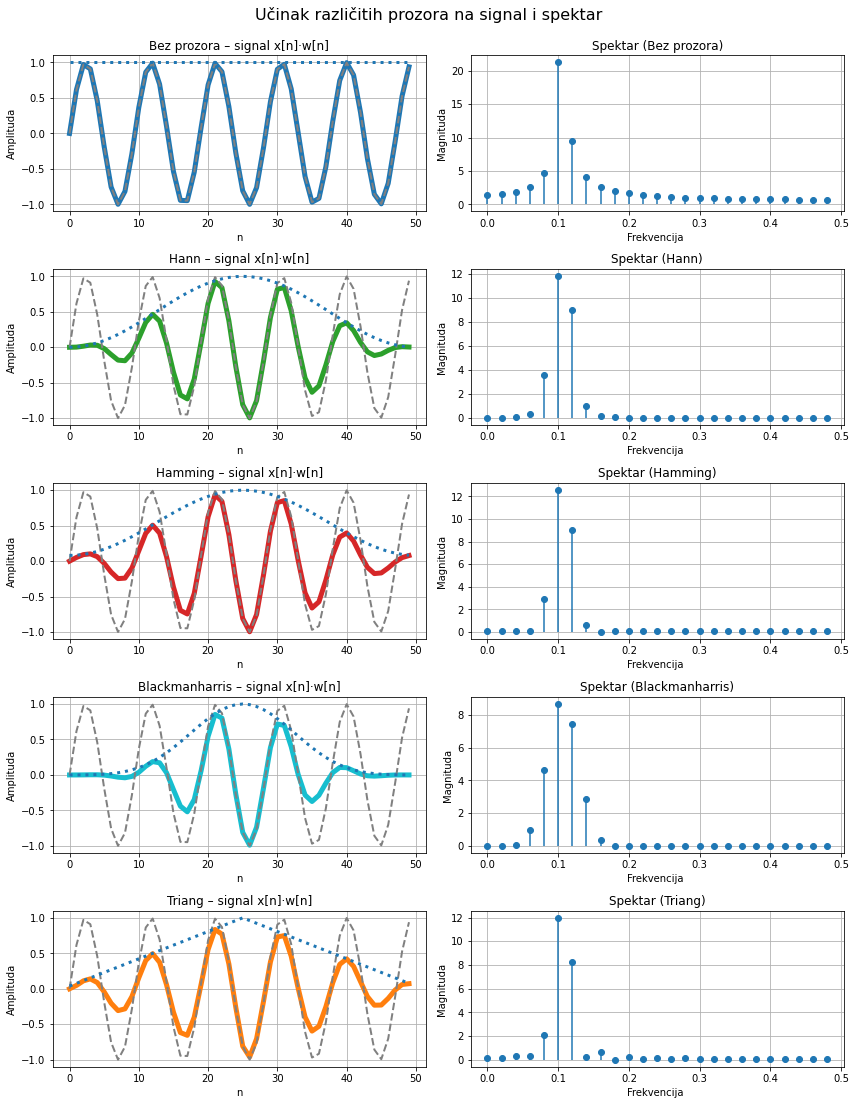

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import get_window
from scipy.fft import fft

N = 50
k = 5.3  # 3 
n = np.arange(N)
x = np.sin(2 * np.pi * k * n / N)

# Prozori koje uspoređujemo
window_types = ['bez prozora','hann', 'hamming', 'blackmanharris', 'triang']
colors = ['tab:blue', 'tab:green', 'tab:red', 'tab:cyan', 'tab:orange']
freqs = np.fft.fftfreq(N, d=1)[:N//2]

fig, axs = plt.subplots(len(window_types), 2, figsize=(12, 15))

for i, win_type in enumerate(window_types):
    
    if(i==0):
        window=np.ones(N)
    else:
        window = get_window(win_type, N)
    x_win = x * window
    X_win = fft(x_win)

    # Lijevo: signal * prozor
    axs[i, 0].plot(n, x_win, color=colors[i], linewidth=5)
    axs[i, 0].plot(n, x, color='grey', linestyle='dashed', linewidth=2)
    axs[i, 0].plot(n, window, color='tab:blue', linestyle='dotted', linewidth=3)
    axs[i, 0].set_title(f'{win_type.capitalize()} – signal x[n]·w[n]')
    axs[i, 0].set_xlabel('n')
    axs[i, 0].set_ylabel('Amplituda')
    axs[i, 0].grid(True)

    # Desno: spektar
    axs[i, 1].stem(freqs, np.abs(X_win[:N//2]), linefmt='', markerfmt='o', basefmt=' ', use_line_collection=True)
    axs[i, 1].set_title(f'Spektar ({win_type.capitalize()})')
    axs[i, 1].set_xlabel('Frekvencija ')
    axs[i, 1].set_ylabel('Magnituda')
    axs[i, 1].grid(True)

plt.tight_layout()
plt.suptitle('Učinak različitih prozora na signal i spektar', fontsize=16, y=1.02)
plt.show()


***

## Inverzna diskretna Fourierova transformacija

Diskretna Fourierova transformacija omogućuje prijelaz iz vremenske u frekvencijsku domenu. Njezin inverz, inverzna diskretna Fourierova transformacija (IDFT), omogućuje povratak iz frekvencijskog niza $X[k]$ u izvorni vremenski niz $x[n]$.

Za DFT smo rekli da je:
$$
X[k] = \sum_{n=0}^{N-1} x[n] \cdot e^{-j2\pi \frac{k}{N}n}
$$

IDFT računamo:
$$
x[n] = \frac{1}{N} \sum_{k=0}^{N-1} X[k] \cdot e^{+j2\pi \frac{k}{N}n}
$$

IDFT izgleda gotovo identično kao DFT. Razlikuju se samo u dva detalja: predznak u eksponentu je pozitivan i cijeli izraz se dijeli s $N$. Pozitivan predznak odgovara inverznoj operaciji, tj. rekonstrukciji signala iz njegovih frekvencijskih komponenti, a faktor $\frac{1}{N}$ osigurava ispravnu normalizaciju signala. Naime, u DFT-u se svaka frekvencijska komponenta dobiva kao suma $N$ uzoraka pa su koeficijenti $X[k]$ proporcionalni toj sumi. Prilikom rekonstrukcije u IDFT-u ponovno zbrajamo $N$ takvih doprinosa, pa bi bez faktora $\frac{1}{N}$ amplituda rezultirajućeg signala bila $N$ puta veća od izvorne. 

***

Dokaz: Uvrstimo definiciju $X[k]$ u izraz za IDFT (koristimo $n'$ kao varijablu sumacije u DFT-u kako bismo je razlikovali od $n$):

$
x[n] = \frac{1}{N} \sum_{k=0}^{N-1} \left( \sum_{n'=0}^{N-1} x[n'] \cdot e^{-j2\pi \frac{k}{N}n'} \right) e^{j2\pi \frac{k}{N} n}
$

Zamijenimo redoslijed sumiranja:

$
x[n] = \frac{1}{N} \sum_{n'=0}^{N-1} x[n'] \left( \sum_{k=0}^{N-1} e^{j2\pi \frac{k}{N}(n - n')} \right)
$

Za unutarnju sumu vrijedi poznati rezultat:

$
\sum_{k=0}^{N-1} e^{j2\pi \frac{k}{N}(n - n')} =
\begin{cases}
N, & \text{ako } n = n' \\
0, & \text{ako } n \ne n'
\end{cases}
$

To možemo zapisati kao $N \cdot \delta[n - n']$:

$
x[n] = \frac{1}{N} \sum_{n'=0}^{N-1} x[n'] \cdot N \cdot \delta[n - n']
$

Faktor $\frac{1}{N} \cdot N = 1$ se poništava, a zbog jediničnog impulsa $\delta[n-n']$ jedino preživljava član za koji je $n' = n$:

$
x[n] = x[n] 
$

čime smo pokazali da IDFT zaista vraća izvorni signal $x[n]$.


***
U praksi, većina obrada signala (poput filtriranja, kompresije, modulacije itd.) puno se jednostavnije i učinkovitije obavlja u frekvencijskoj domeni, a IDFT omogućuje da se, nakon obrade, signal vrati u vremensku domenu.

Jedna od najvažnijih primjena IDFT-a je filtriranje signala, koje se provodi u nekoliko koraka:
- Signal prebacimo DFT-om u frekvencijsku domenu.
- Modificiramo njegove frekvencijske komponente:
  - prigušimo ili uklonimo neželjene visokofrekvencijske komponente → niskopropusni filtar,
  - prigušimo ili uklonimo neželjene niskofrekvencijske komponente → visokopropusni filtar,
  - propustimo samo određeni frekvencijski pojas → pojasni filtar.
- Na kraju primjenjujemo IDFT kako bismo dobili filtrirani signal natrag u vremenskom obliku.

***

Što se tiče implementacije, IDFT je dostupna u Python bibliotekama _NumPy_ i _SciPy_. Baš kao što se DFT računa funkcijom `fft`, IDFT se implementira pomoću funkcije `ifft` u obje biblioteke. Ako koristimo realnu Fourierovu transformaciju pomoću `rfft`, njezin inverzni pandan je `irfft`.

U nastavku su dani primjeri implementacije IDFT-a.

Prvi prikazuje signal $x[n]$ koji je zbroj dviju sinusoida frekvencija 1 Hz i 3 Hz. Nakon što izračunamo DFT, iz spektra izoliramo doprinos svake frekvencijske komponente zasebno: za frekvenciju $f$ u spektru postoje dva simetrična koeficijenta (na indeksima $k$ i $N-k$) pa uzimamo oba i rekonstruiramo odgovarajuću sinusoidu primjenom IDFT-a samo na ta dva koeficijenta.
Gornji graf prikazuje originalni signal, srednji njegovi amplitudni spektar, a donji rekonstrukciju: vidimo da komponenta od 1 Hz i komponenta od 3 Hz, svaka prikazana zasebno po uzorku, u svakoj točki daju zbroj koji je jednak originalnom signalu $x[n]$.

Drugi primjer prikazuje jednostavni niskopropusni filtar koji odbacuje frekvencije iznad $20 \text{ Hz}$.


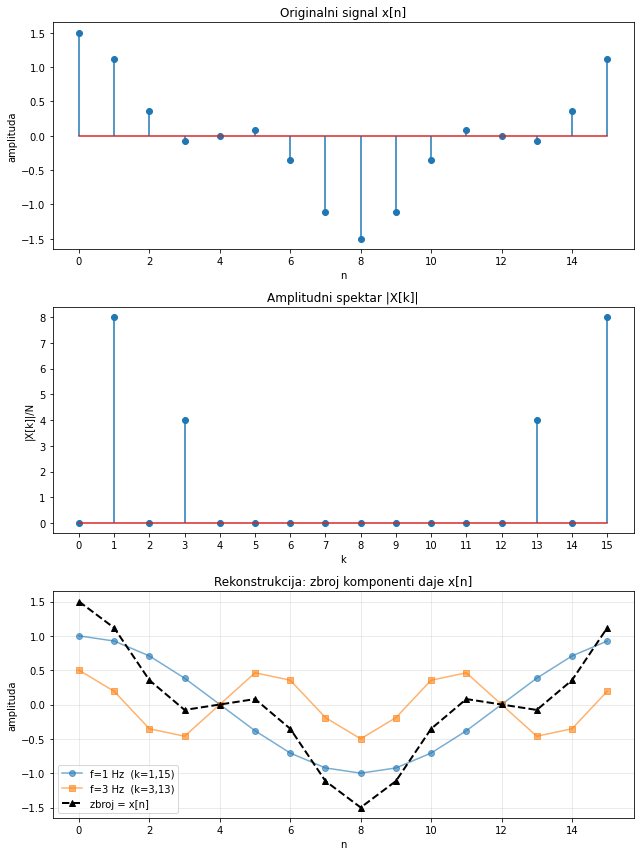

In [17]:
import numpy as np
import matplotlib.pyplot as plt

fs = 16
N = 16
n = np.arange(N)
t = n / fs

f1, f2 = 1, 3

x = np.cos(2 * np.pi * f1 * t) + 0.5 * np.cos(2 * np.pi * f2 * t)

X = np.fft.fft(x)
k = np.arange(N)

amplituda = np.abs(X) 

# maska: prikaži fazu samo tamo gdje je amplituda značajna
prag = 1e-10
faza = np.where(amplituda > prag, np.angle(X), np.nan)

k1, k2 = int(f1 * N / fs), int(f2 * N / fs)
k1c, k2c = N - k1, N - k2

komponenta_f1 = np.real((1/N) * X[k1]  * np.exp(1j * 2 * np.pi * k1  * n / N)) \
              + np.real((1/N) * X[k1c] * np.exp(1j * 2 * np.pi * k1c * n / N))

komponenta_f2 = np.real((1/N) * X[k2]  * np.exp(1j * 2 * np.pi * k2  * n / N)) \
              + np.real((1/N) * X[k2c] * np.exp(1j * 2 * np.pi * k2c * n / N))

x_rekonstruirano = komponenta_f1 + komponenta_f2

fig, axes = plt.subplots(3, 1, figsize=(9, 12))

axes[0].stem(n, x)
axes[0].set_title("Originalni signal x[n]")
axes[0].set_xlabel("n")
axes[0].set_ylabel("amplituda")

axes[1].stem(k, amplituda)
axes[1].set_title("Amplitudni spektar |X[k]|")
axes[1].set_xlabel("k")
axes[1].set_ylabel("|X[k]|/N")
axes[1].set_xticks(k)

axes[2].plot(n, komponenta_f1, 'o-', alpha=0.6, label=f"f={f1} Hz  (k={k1},{k1c})")
axes[2].plot(n, komponenta_f2, 's-', alpha=0.6, label=f"f={f2} Hz  (k={k2},{k2c})")
axes[2].plot(n, x_rekonstruirano, 'k^--', linewidth=2, label="zbroj = x[n]")
axes[2].set_title("Rekonstrukcija: zbroj komponenti daje x[n]")
axes[2].set_xlabel("n")
axes[2].set_ylabel("amplituda")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

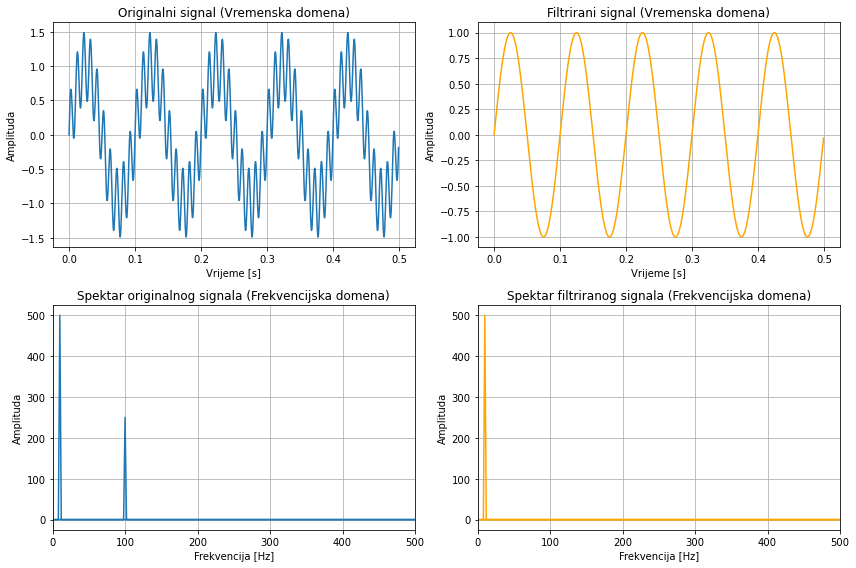

In [14]:
import numpy as np
import matplotlib.pyplot as plt

fs = 2000  
T = 1.0 / fs  
n = np.arange(0, 1000)  
f1 = 10  
f2 = 100  

signal = np.sin(2 * np.pi * f1 * n * T) + 0.5 * np.sin(2 * np.pi * f2 * n * T)

signal_fft = np.fft.fft(signal)

cutoff_freq = 20
N = len(signal)
freq = np.fft.fftfreq(N, T)

filter_mask = np.abs(freq) < cutoff_freq  # ostavlja samo one spektralne komponente koje su ispod cutoff_freq
filtered_signal_fft = signal_fft * filter_mask

filtered_signal = np.fft.ifft(filtered_signal_fft)

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.plot(n * T, signal, label='Originalni signal')
plt.title('Originalni signal (Vremenska domena)')
plt.xlabel('Vrijeme [s]')
plt.ylabel('Amplituda')
plt.grid(True)

plt.subplot(2, 2, 2)
plt.plot(n * T, filtered_signal.real, label='Filtrirani signal', color='orange')
plt.title('Filtrirani signal (Vremenska domena)')
plt.xlabel('Vrijeme [s]')
plt.ylabel('Amplituda')
plt.grid(True)

plt.subplot(2, 2, 3)
plt.plot(freq, np.abs(signal_fft), label='Spektar originalnog signala')
plt.title('Spektar originalnog signala (Frekvencijska domena)')
plt.xlabel('Frekvencija [Hz]')
plt.ylabel('Amplituda')
plt.xlim(0, 500)  
plt.grid(True)

plt.subplot(2, 2, 4)
plt.plot(freq, np.abs(filtered_signal_fft), label='Spektar filtriranog signala', color='orange')
plt.title('Spektar filtriranog signala (Frekvencijska domena)')
plt.xlabel('Frekvencija [Hz]')
plt.ylabel('Amplituda')
plt.xlim(0, 500)  
plt.grid(True)

plt.tight_layout()
plt.show()


***


## Konvolucija u frekvencijskoj domeni

Znamo da konvolucija glasi:

$
y[n]=x*h=\sum_{k=0}^{N-1} x[k] \cdot h[n-k]
$

Zanima nas kako izgleda frekvencijski spektar tog signala: $Y[k]=DFT(x*h)$

Prvo moramo odrediti kako provesti konvoluciju u slučaju DFT-a budući da, kao i kod pomaka u DFT-u, pretpostavljamo da se signali nad kojima provodimo konvoluciju periodički ponavljaju. Zato uvodimo ideju __kružne konvolucije__ koja uzima u obzir tu pretpostavku:

$
y[n]=\sum_{k=0}^{N-1} x[k] \cdot h[(n-k) \bmod N]
$

Konvolucijski teorem tada glasi:

Ako su $x[n]$ i $h[n]$ signali duljine $N$, a $y[n] = x*h$ njihova kružna konvolucija, tada za spektar $Y$ vrijedi:
$$
\begin{equation}
Y[k]=X[k] \cdot H[k]
\end{equation}
$$

Dakle, konvolucija u vremenskoj domeni je zapravo množenje u frekvencijskoj domeni.

Pokazat ćemo da je tako:


DFT od $ y[n] $ je

$
Y[k] = \sum_{n=0}^{N-1} y[n] e^{-j \frac{2\pi}{N} kn}.
$

Ubacujemo izraz za $ y[n] $ (samo umjesto $k$ koristimo $m$ kako bismo razlikovali od varijable $k$ iz prethodnog izraza):

$
Y[k] = \sum_{n=0}^{N-1} \left( \sum_{m=0}^{N-1} x[m] h[(n-m) \bmod N] \right) e^{-j \frac{2\pi}{N} kn}.
$

Promijenimo redoslijed sumiranja:

$
Y[k] = \sum_{m=0}^{N-1} x[m] \left( \sum_{n=0}^{N-1} h[(n-m) \bmod N] e^{-j \frac{2\pi}{N} kn} \right).
$

Uvedimo zamjenu varijable $ l = (n-m) \bmod N $, što znači da je $ n = (l+m) \bmod N $.
Kada $ n $ prolazi od $ 0 $ do $ N-1 $, tada i $ l $ prolazi od $ 0 $ do $ N-1 $ jer je sve $\bmod N$ pa možemo jednostavnije zapisati:

$
Y[k] = \sum_{m=0}^{N-1} x[m] \left( \sum_{l=0}^{N-1} h[l] e^{-j \frac{2\pi}{N} k(l+m)} \right).
$

Rastavimo eksponencijal:

$
Y[k] = \sum_{m=0}^{N-1} x[m] e^{-j \frac{2\pi}{N} km} \left( \sum_{l=0}^{N-1} h[l] e^{-j \frac{2\pi}{N} kl} \right).
$

Primijetimo da je unutarnja suma samo $ H[k] $, pa:

$
Y[k] = H[k] \sum_{m=0}^{N-1} x[m] e^{-j \frac{2\pi}{N} km}.
$

Prepoznajemo preostalu sumu kao $ X[k]$, odnosno pokazali smo da je:

$
Y[k] = X[k] \cdot H[k].
$


Ovime je i jasnije zašto je faktor $e^{-j 2\pi \frac{k}{N} d}$ iz poglavlja o pomaku jednak $\text{DFT}(\delta[n-d])$: kružni pomak signala $x[n]$ za $d$ uzoraka ekvivalentan je kružnoj konvoluciji $x[n] * \delta[n-d]$, a prema konvolucijskom teoremu to u frekvencijskoj domeni postaje množenje $X[k] \cdot \text{DFT}(\delta[n-d])$.

Konvolucijski se teorem često koristi u praksi. Umjesto direktne konvolucije koja je spora za velike signale, signal se prebaci u frekvencijsku domenu, pomnoži s frekvencijskim odzivom filtra i zatim vrati u vremensku domenu. Time se složenost računanja značajno smanjuje, što omogućuje učinkovitu obradu dugih signala.
LTI sustavi se u frekvencijskoj domeni svode na jednostavno množenje sa svojim frekvencijskim odzivom.


***

Implementacija konvolucije u __SciPy biblioteci__ (`scipy.signal.convolve()`) daje mogućnost provedbe konvolucije na način da se signali prvo prebace u frekvencijsku domenu, pomnože i onda se inverzom dobije rezultat konvolucije. To se može postaviti pomoću argumenta `method` (može biti `direct` koji računa kroz obične sume, `fft` koji računa množenjem u frekvencijskoj domeni ili `auto` koji računa ovisno o duljinama signala). Za dva signala jednakih duljina ($N$) to znači da će umjesto složenosti $O(N^2)$ složenost algoritma za konvoluciju sada biti $O(N\log N)$ jer nam za taj pristup treba:

 1. nadopuna nulama (_eng. zero-padding_) ako signali nisu jednakih duljina: do $N$ koraka 
 2. Dva FFT-a (za $X$ i $H$): složenost svakog je $N \log N$, ukupno je $2N \log N$
 3. množenje: $N$ koraka
 4. IFFT: $N \log N$
 
Dakle, imamo $N+2N\log N+N+N\log N$ što nam daje ukupnu složenost algoritma $O(N \log N)$. Opet kao i kod FFT-a, za veliki $N$ takav će se algoritam puno brže izvršiti.

Znajući ovo svojstvo, jednostavnije je pokazati da za konvoluciju vrijede svojstva komutativnosti i asocijativnosti jer na primjer u frekvencijskoj domeni za neka tri spektra vrijedi $H\cdot (G \cdot X)=(H\cdot G) \cdot X$ pa u vremenskoj mora vrijediti i $h*(g*x)=(h*g)*x$.


***

U nastavku je primjer koji prikazuje konvolucijski teorem.

Ulazni signal $x[n]$ je sinus od 5 Hz kojemu je dodan bijeli šum zbog čega je izvorna sinusoida gotovo neprepoznatljiva u vremenskoj domeni. U spektru $X[k]$ se vidi jedan šiljak na 5 Hz okružen manjim impulsima ravnomjerno raspoređenima jer šum jednako utječe na sve frekvencije.

Drugi red prikazuje Gaussov filtar $h[n]$. U vremenskoj domeni to je zvonolika krivulja koja predstavlja težinsko usrednjavanje: svaki izlazni uzorak je kombinacija okolnih ulaznih uzoraka, pri čemu bliži susjedi dobivaju veću težinu, a dalji manju. Nagli skokovi i oscilacije koje čine šum brzo mijenjaju predznak pa se međusobno poništavaju u tom usrednjavanju, dok spora sinusoida ostaje gotovo netaknuta. U frekvencijskoj domeni ta intuicija postaje jasnija. Gaussova krivulja ima Gaussov frekvencijski odziv $H[k]$, što znači da se radi o niskopropusnom filtru koji visoke frekvencije (šum) gasi, a niske propušta.

Treći red prikazuje rezultat. U vremenskoj domeni filtrirani signal $y[n] = x[n] * h[n]$ ponovno prati oblik sinusoide (šum je uklonjen). U spektru $Y[k]$ vidimo zašto je to tako. Prema konvolucijskom teoremu vrijedi $Y[k] = X[k] \cdot H[k]$. Dakle umjesto konvolucije u vremenskoj domeni dovoljno je spektar ulaza pomnožiti s frekvencijskim odzivom filtra. Šiljak na 5 Hz ostaje netaknut, a sve ostalo je prigušeno. 


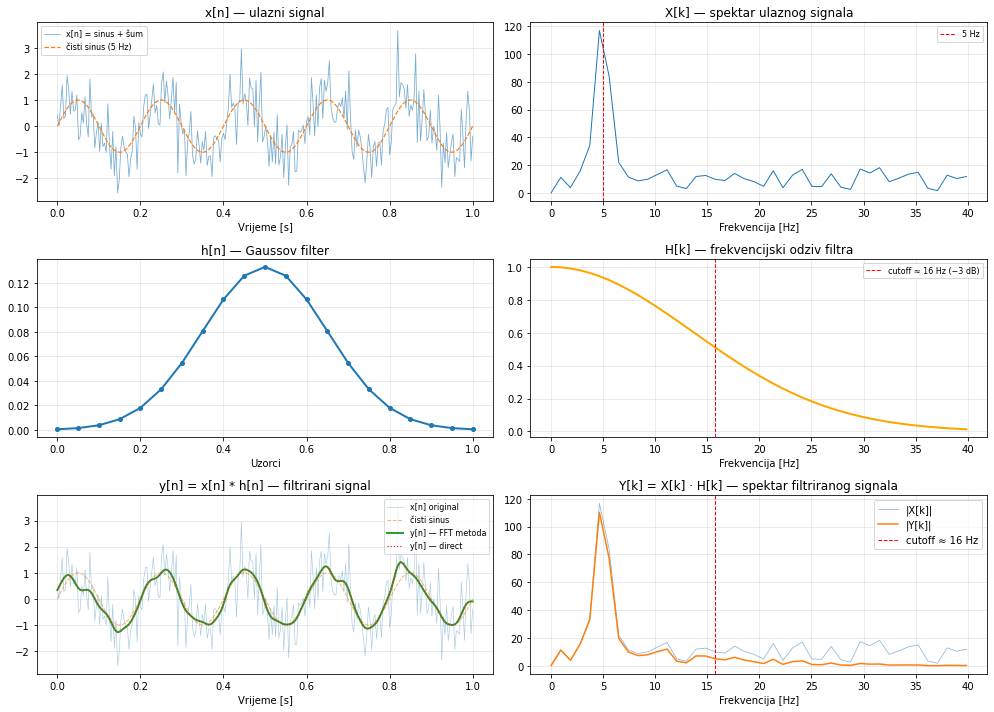

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve

N = 256
t = np.linspace(0, 1, N)
np.random.seed(42)

čisti_sinus = np.sin(2 * np.pi * 5 * t)
signal = čisti_sinus + 0.8 * np.random.randn(N)

M = 21
m = np.arange(M) - M // 2
h = np.exp(-m**2 / (2 * 3.0**2))
h /= h.sum()

y_direct = convolve(signal, h, mode='same', method='direct')

N_pad = N + M - 1
X = np.fft.rfft(signal, n=N_pad)
H = np.fft.rfft(h,      n=N_pad)
Y = X * H
y_fft = np.fft.irfft(Y, n=N_pad)[M//2 : M//2 + N]


freqs  = np.fft.rfftfreq(N_pad, d=1/N)
fmax   = 40
maska  = freqs <= fmax
cutoff = freqs[np.argmin(np.abs(np.abs(H) - np.abs(H[0])/2))]

fig, axes = plt.subplots(3, 2, figsize=(14, 10))

axes[0,0].plot(t, signal,      lw=0.8, alpha=0.6, label='x[n] = sinus + šum')
axes[0,0].plot(t, čisti_sinus, lw=1.2, ls='--',   label='čisti sinus (5 Hz)')
axes[0,0].set(title='x[n] — ulazni signal', xlabel='Vrijeme [s]')
axes[0,0].legend(fontsize=8)

axes[0,1].plot(freqs[maska], np.abs(X)[maska], lw=1)
axes[0,1].axvline(5, color='red', ls='--', lw=1, label='5 Hz')
axes[0,1].set(title='X[k] — spektar ulaznog signala', xlabel='Frekvencija [Hz]')
axes[0,1].legend(fontsize=8)

axes[1,0].plot(np.linspace(0,1,M), h, lw=2, marker='o', ms=4)
axes[1,0].set(title='h[n] — Gaussov filter', xlabel='Uzorci')

axes[1,1].plot(freqs[maska], np.abs(H)[maska], color='orange', lw=2)
axes[1,1].axvline(cutoff, color='red', ls='--', lw=1,
                  label=f'cutoff ≈ {cutoff:.0f} Hz (−3 dB)')
axes[1,1].set(title='H[k] — frekvencijski odziv filtra', xlabel='Frekvencija [Hz]')
axes[1,1].legend(fontsize=8)

axes[2,0].plot(t, signal,     lw=0.6, alpha=0.4, label='x[n] original')
axes[2,0].plot(t, čisti_sinus, lw=1,  ls='--', alpha=0.6, label='čisti sinus')
axes[2,0].plot(t, y_fft,      lw=2,              label='y[n] — FFT metoda')
axes[2,0].plot(t, y_direct,   lw=1.2, ls=':',    label='y[n] — direct')
axes[2,0].set(title='y[n] = x[n] * h[n] — filtrirani signal', xlabel='Vrijeme [s]')
axes[2,0].legend(fontsize=8)

axes[2,1].plot(freqs[maska], np.abs(X)[maska], lw=0.8, alpha=0.5, label='|X[k]|')
axes[2,1].plot(freqs[maska], np.abs(Y)[maska], lw=1.5,             label='|Y[k]|')
axes[2,1].axvline(cutoff, color='red', ls='--', lw=1, label=f'cutoff ≈ {cutoff:.0f} Hz')
axes[2,1].set(title='Y[k] = X[k] · H[k] — spektar filtriranog signala', xlabel='Frekvencija [Hz]')
axes[2,1].legend()

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()